# CityFlow · 01 — From station events to a forecasting problem

**A reproducible, city-configurable exploration report — before machine learning.**

This notebook is designed to accompany CityFlow’s reusable Python scripts. It answers *methodological questions*: what data do we have, which observations are trustworthy, how do we define a forecast without leakage, and what can a simple rule already predict?

The notebook explains **why** each statistic is calculated. It deliberately does **not** provide hard-coded conclusions about Heidelberg or Bergamo: the figures and tables are calculated from the selected city’s files.

**Flow:** raw station-change events → cleaned hourly states → one-hour-ahead labels → chronological validation → simple baselines → questions for ML.

> **Scope:** EDA and baselines only. No machine-learning models are trained here. The final chronological test period is not evaluated or used to select models. Data-quality summaries may describe the whole recording period, but outcome-based diagnostics use training/validation data only.

## 0 · Setup

**Recommended workflow:** run this notebook in **VS Code** with the project's `.venv` selected as the Jupyter kernel. Install the VS Code **Jupyter** extension if necessary.

From the CityFlow root in PowerShell (once):

```powershell
.\.venv\Scripts\Activate.ps1
python -m pip install duckdb pandas numpy matplotlib ipykernel jinja2
python -m ipykernel install --user --name cityflow --display-name "Python (CityFlow)"
```

Put the notebook in `CityFlow/notebooks/01_data_exploration.ipynb`. If the kernel is already your `.venv`, the last command is optional.

Change **`CITY`** below to analyze another extracted city. By default, the notebook **reads** the existing Parquet/CSV reports. Set the switches to `True` only when you explicitly want to rerun the preprocessing scripts; the original raw-data audit can take time.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import subprocess
import sys

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ---- Project configuration -------------------------------------------------
CITY = "heidelberg"               # e.g. "bergamo"
RUN_AUDIT = False                # Run src/audit_city.py before loading reports
REBUILD_HOURLY = False           # Run src/build_hourly.py before loading data
STATION_MAX_AGE_HOURS = 6        # Used only if REBUILD_HOURLY is True
FEED_MAX_AGE_HOURS = 2           # Used only if REBUILD_HOURLY is True
EXAMPLE_STATION_ID = None        # None = choose a high-coverage station
EXAMPLE_DAYS = 5


def locate_project_root():
    """Work whether VS Code starts the kernel in the root or notebooks/."""
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "src").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError(
        "Cannot locate CityFlow root (a folder containing src/ and data/). "
        "Open CityFlow as the VS Code workspace, or change the kernel cwd."
    )


ROOT = locate_project_root()
DATA = ROOT / "data" / CITY.lower()
REPORT = ROOT / "reports" / CITY.lower()

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print(f"Project root: {ROOT}")
print(f"City:         {CITY}")
print(f"Python:       {sys.executable}")

Project root: c:\Users\ricca\Desktop\CityFlow
City:         heidelberg
Python:       c:\Users\ricca\Desktop\CityFlow\.venv\Scripts\python.exe


### Reuse the existing Python pipeline

The scripts in `src/` remain the **source of truth** for data extraction and reconstruction. The notebook is a readable report, not a second implementation of your entire data pipeline.

Use `RUN_AUDIT=True` or `REBUILD_HOURLY=True` in the preceding cell if the source data or preprocessing settings have changed. Otherwise this cell simply verifies the expected files.

In [2]:
def run_project_script(filename, arguments):
    script = ROOT / "src" / filename
    if not script.exists():
        raise FileNotFoundError(f"Missing preprocessing script: {script}")
    command = [sys.executable, str(script), *arguments]
    print("Running:", " ".join(command))
    subprocess.run(command, cwd=ROOT, check=True)


if RUN_AUDIT:
    run_project_script("audit_city.py", ["--city", CITY])

if REBUILD_HOURLY:
    run_project_script(
        "build_hourly.py",
        ["--city", CITY,
         "--station-age", str(STATION_MAX_AGE_HOURS),
         "--feed-age", str(FEED_MAX_AGE_HOURS)],
    )

hourly_path = DATA / "hourly_observations.parquet"
ml_path = DATA / "hourly_ml.parquet"
for required in (hourly_path, ml_path):
    if not required.is_file():
        raise FileNotFoundError(
            f"Missing {required}. Run src/build_hourly.py --city {CITY} "
            "from the project root, or enable REBUILD_HOURLY above."
        )

con = duckdb.connect()
con.read_parquet(str(hourly_path)).create_view("hourly")
con.read_parquet(str(ml_path)).create_view("ml")

print("Hourly and modelling Parquet files found; DuckDB views ready.")

Hourly and modelling Parquet files found; DuckDB views ready.


## 1 · Data structure: observations are not evenly sampled

The original `station_status` file records **station status changes**, not a regular sequence of hourly snapshots. Consequently:

- **Event count** measures how often records were created; it is not the duration a station spent in a particular state.
- **No event** can mean that the station remained unchanged *or* that data collection was interrupted.
- **Station metadata** and the actual status observations are different things: a registered station might have few usable online hours.

We first inspect the input reports and event activity before interpreting any forecast label.

In [3]:
overview = con.execute("""
    SELECT
        COUNT(*) AS station_hours,
        COUNT(DISTINCT station_id) AS reconstructed_stations,
        COUNT(*) FILTER (WHERE usable) AS usable_station_hours,
        MIN(hour_time) AS first_hour_utc,
        MAX(hour_time) AS last_hour_utc
    FROM hourly
""").df().iloc[0]

model_overview = con.execute("""
    SELECT
        COUNT(*) AS eligible_pairs,
        COUNT(DISTINCT station_id) AS model_stations
    FROM ml
""").df().iloc[0]

summary = pd.DataFrame([
    ("Stations in hourly grid", int(overview.reconstructed_stations)),
    ("Candidate station-hours", int(overview.station_hours)),
    ("Usable station-hours", int(overview.usable_station_hours)),
    ("Usable coverage", f"{overview.usable_station_hours / overview.station_hours:.1%}"),
    ("Eligible one-hour pairs", int(model_overview.eligible_pairs)),
    ("Stations in ML sample", int(model_overview.model_stations)),
    ("Hourly grid begins (UTC)", datetime.fromtimestamp(int(overview.first_hour_utc), timezone.utc)),
    ("Hourly grid ends (UTC)", datetime.fromtimestamp(int(overview.last_hour_utc), timezone.utc)),
], columns=["Indicator", "Value"])
display(summary)

,Indicator,Value
0,Stations in hourly grid,49
1,Candidate station-hours,380191
2,Usable station-hours,313801
3,Usable coverage,82.5%
4,Eligible one-hour pairs,305415
5,Stations in ML sample,49
6,Hourly grid begins (UTC),2022-08-26 15:00:00+00:00
7,Hourly grid ends (UTC),2023-07-15 21:00:00+00:00


### Daily event activity and possible collection interruptions

A **city-wide zero-event day** is worth flagging: it may indicate that the source feed was unavailable, especially if the same dates occur in multiple cities. It is **not**, by itself, proof of an outage. Similarly, a very long interval between station changes is not definitive proof that an individual station was offline.

The optional `daily_activity.csv` report is created by `audit_city.py`. If it is missing, the notebook calculates the daily event counts directly from `station_status.parquet`.

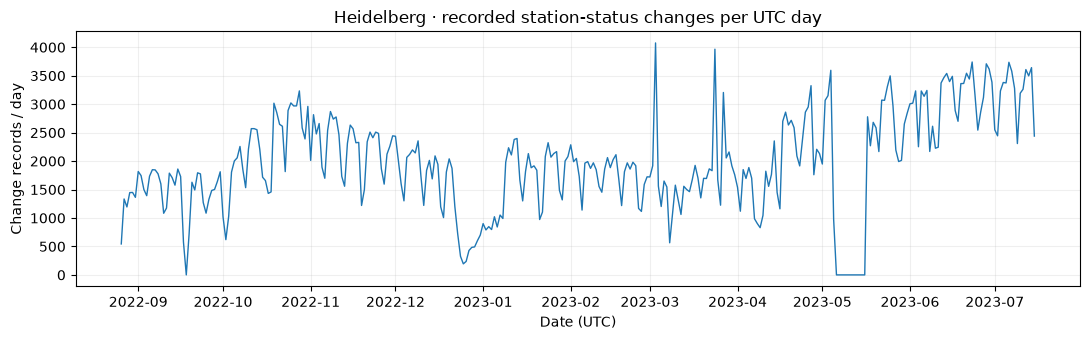

Days with no recorded station changes: 12


,Zero-event UTC date
0,2022-09-18
1,2023-05-06
2,2023-05-07
3,2023-05-08
4,2023-05-09
5,2023-05-10
6,2023-05-11
7,2023-05-12
8,2023-05-13
9,2023-05-14


In [4]:
daily_file = REPORT / "daily_activity.csv"
if daily_file.exists():
    daily = pd.read_csv(daily_file)
    daily["date"] = pd.to_datetime(daily["date_utc"], utc=True)
else:
    event_file = DATA / "station_status.parquet"
    if not event_file.exists():
        raise FileNotFoundError(
            "Need reports/<city>/daily_activity.csv or "
            "data/<city>/station_status.parquet for daily event activity."
        )
    daily = con.execute("""
        SELECT CAST(FLOOR(time / 86400) * 86400 AS BIGINT) AS day_epoch,
               COUNT(*) AS status_records,
               COUNT(DISTINCT station_id) AS stations_with_records
        FROM read_parquet(?)
        GROUP BY day_epoch ORDER BY day_epoch
    """, [str(event_file)]).df()
    daily["date"] = pd.to_datetime(daily["day_epoch"], unit="s", utc=True)

# Ensure days with no events appear (including when CSV was built with rows only for observed days).
daily = (daily.set_index("date")
              .sort_index()[["status_records", "stations_with_records"]]
              .asfreq("D", fill_value=0)
              .reset_index())
zero_days = daily.loc[daily["status_records"].eq(0), "date"]

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily["date"], daily["status_records"], linewidth=1)
ax.set(title=f"{CITY.title()} · recorded station-status changes per UTC day",
       xlabel="Date (UTC)", ylabel="Change records / day")
plt.tight_layout()
plt.show()

print(f"Days with no recorded station changes: {len(zero_days)}")
if len(zero_days):
    display(pd.DataFrame({"Zero-event UTC date": zero_days.dt.date.to_numpy()}))

### Coverage is a station-level property

A city can look complete overall while some stations have poor observation coverage. Examining coverage *per station* prevents a handful of highly active stations from hiding problems elsewhere.

The chart below uses the same **usable** flag as the reconstruction script. The exact definition depends on the freshness limits and validity checks selected when `build_hourly.py` was run.

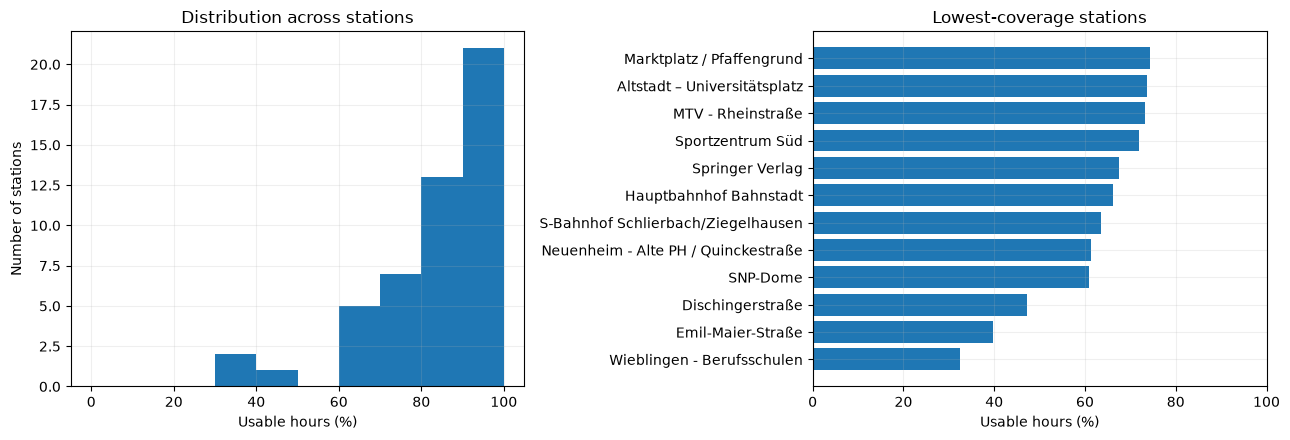

,station_name,grid_hours,usable_hours,coverage_pct
0,Wieblingen - Berufsschulen,7759,2513,32.400
1,Emil-Maier-Straße,7759,3082,39.700
2,Dischingerstraße,7759,3665,47.200
3,SNP-Dome,7759,4725,60.900
4,Neuenheim - Alte PH / Quinckestraße,7759,4756,61.300
5,S-Bahnhof Schlierbach/Ziegelhausen,7759,4932,63.600
6,Hauptbahnhof Bahnstadt,7759,5142,66.300
7,Springer Verlag,7759,5241,67.500
8,Sportzentrum Süd,7759,5577,71.900
9,MTV - Rheinstraße,7759,5686,73.300


In [5]:
coverage = con.execute("""
    SELECT station_id,
           MAX(station_name) AS station_name,
           COUNT(*) AS grid_hours,
           COUNT(*) FILTER (WHERE usable) AS usable_hours,
           AVG(CAST(usable AS INTEGER)) AS fraction_usable
    FROM hourly
    GROUP BY station_id
    ORDER BY fraction_usable ASC
""").df()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(100 * coverage["fraction_usable"], bins=np.arange(0, 105, 10))
axes[0].set(title="Distribution across stations", xlabel="Usable hours (%)", ylabel="Number of stations")

low = coverage.head(min(12, len(coverage))).sort_values("fraction_usable")
axes[1].barh(low["station_name"], low["fraction_usable"] * 100)
axes[1].set(title="Lowest-coverage stations", xlabel="Usable hours (%)", xlim=(0, 100))
plt.tight_layout()
plt.show()

display(coverage.assign(coverage_pct=100 * coverage.fraction_usable)
        [["station_name", "grid_hours", "usable_hours", "coverage_pct"]]
        .head(12).round(1))

## 2 · From a change log to hourly states

For every UTC hour and station, `build_hourly.py` retrieves the **latest event no later than that hour** (an *as-of join*). This is also called *last observation carried forward*. Importantly, it does **not** interpolate between a past and a future observation: at forecast time, future station states are unknown.

Two safeguards restrict forward filling:

1. **Station freshness** — the last station update must be recent enough.
2. **Feed freshness** — the city must have at least one sufficiently recent recorded event, giving us some evidence the overall collection system is active.

These are practical assumptions, **not guarantees** of perfect data. The reconstructed state is marked unusable when its validity checks fail; missing values are preserved rather than filled indefinitely.

We visualize a real station to see the difference between observed changes, carried-forward states, and missing intervals.

In [6]:
station_id = (coverage.iloc[-1]["station_id"] if EXAMPLE_STATION_ID is None
              else EXAMPLE_STATION_ID)

# Choose an interval early in this station's usable history.
bounds = con.execute("""
    SELECT MIN(hour_time), MAX(hour_time)
    FROM hourly
    WHERE station_id = ? AND usable
""", [station_id]).fetchone()

if bounds[0] is None:
    print("No usable hourly observations for the chosen station.")
else:
    window_start = int(bounds[0])
    window_end = window_start + int(EXAMPLE_DAYS * 86400)
    example = con.execute("""
        SELECT hour_time, available_bikes, usable,
               state_age_minutes
        FROM hourly
        WHERE station_id = ?
          AND hour_time BETWEEN ? AND ?
        ORDER BY hour_time
    """, [station_id, window_start, window_end]).df()

    example["local_time"] = pd.to_datetime(
        example["hour_time"], unit="s", utc=True
    ).dt.tz_convert("Europe/Berlin")

    station_name = coverage.loc[
        coverage.station_id.eq(station_id), "station_name"
    ].iloc[0]

    fig, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(example["local_time"], example["available_bikes"],
            marker=".", markersize=3, linewidth=1)
    ax.set(title=f"Hourly state reconstruction · {station_name}",
           xlabel="Local time (Europe/Berlin)", ylabel="Rentable bikes")
    plt.tight_layout()
    plt.show()
    print("Gaps in the line represent unavailable hourly states, not zero bikes.")

NotImplementedException: Not implemented Error: Unable to transform python value of type '<class 'numpy.int64'>' to DuckDB LogicalType

### How sensitive is coverage to the station-age threshold?

Freshness is a modelling choice. A strict threshold discards more hours but reduces reliance on old states; a loose threshold retains more training examples but risks stale availability. The following is a **nested sensitivity check**: it can only make the *existing* hourly dataset stricter. To test thresholds larger than the one used in `build_hourly.py`, first rebuild the data with a larger limit.

For this comparison the feed freshness requirement and all other validity checks remain unchanged.

,Maximum station age (hours),Usable candidate hours,Usable coverage
0,1,191518,50.4%
1,2,242575,63.8%
2,3,270461,71.1%
3,4,289325,76.1%
4,6,313801,82.5%


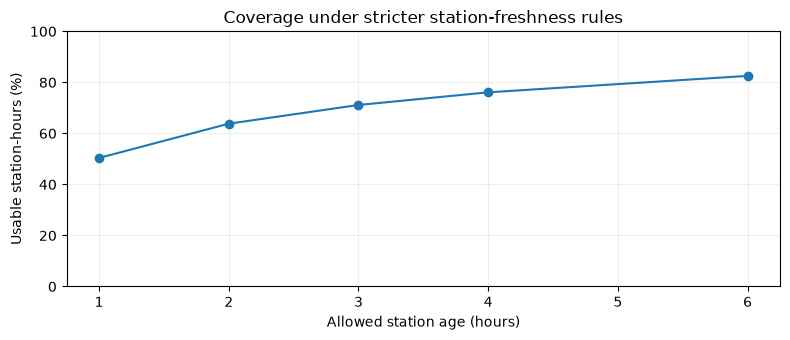

In [7]:
candidate_age_h = [1, 2, 3, 4, 6]
rows = []
for h in candidate_age_h:
    usable_at_h = con.execute("""
        SELECT COUNT(*) FILTER (
            WHERE usable AND state_age_minutes <= ?
        )
        FROM hourly
    """, [60 * h]).fetchone()[0]
    rows.append({"Maximum station age (hours)": h,
                 "Usable candidate hours": usable_at_h,
                 "Usable coverage": usable_at_h / int(overview.station_hours)})
sensitivity = pd.DataFrame(rows)
display(sensitivity.style.format({"Usable coverage": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(sensitivity["Maximum station age (hours)"],
        100 * sensitivity["Usable coverage"], marker="o")
ax.set(title="Coverage under stricter station-freshness rules",
       xlabel="Allowed station age (hours)", ylabel="Usable station-hours (%)",
       ylim=(0, 100))
plt.tight_layout()
plt.show()

## 3 · Define the forecast target without leaking the future

CityFlow's original target is binary:

\[
y_{s,t} = \mathbf{1}\!\left[B_s(t+1\,\mathrm{hour}) \leq 2\right].
\]

At **prediction time** \(t\), we know the latest valid bike count and can compute features based on **past events**. We may not use the station state at \(t+1\) as an input feature; that future value is only the **label** used to train/evaluate a model.

In the current `hourly_ml.parquet`, a station-hour pair is included only if both the issue state and the target state pass the preprocessing quality rules. This means our estimates describe **eligible hours**, not necessarily every hour in the city's history.

A second outcome will help us understand the operational challenge: **new shortage onset**, defined only when there are **more than two bikes now** but two or fewer after one hour.

## 4 · Chronological train / validation / test split

Time series are not independent random rows. A random split would mix nearby hours and allow an evaluation that benefits from almost identical station states seen during training.

We use the previously established calendar-time boundaries: first 70% of the time span for **training**, next 15% for **validation**, last 15% for a **held-out final test**. Every station uses the same boundaries. Importantly, a sample is included in a split only if its *one-hour target* lies within that split.

The notebook reads **training and validation labels only**. It prints the calendar boundary of the test period but does not inspect its outcomes.

In [8]:
begin, finish = con.execute("""
    SELECT MIN(issue_time), MAX(target_time) FROM ml
""").fetchone()
train_end = begin + int(0.70 * (finish - begin))
val_end = begin + int(0.85 * (finish - begin))

# We deliberately do not load test labels into Python.
trainval = con.execute("""
    SELECT station_id, issue_time, target_time,
           current_bikes, shortage_in_1h
    FROM ml
    WHERE target_time <= ?
""", [val_end]).df()

train = trainval.loc[trainval["target_time"] <= train_end].copy()
val = trainval.loc[(trainval["issue_time"] > train_end)
                   & (trainval["target_time"] <= val_end)].copy()

if train.empty or val.empty:
    raise ValueError("Training or validation partition is empty.")

split_table = pd.DataFrame([
    {"Split": "Train", "Samples": len(train),
     "Shortage rate": train.shortage_in_1h.mean()},
    {"Split": "Validation", "Samples": len(val),
     "Shortage rate": val.shortage_in_1h.mean()},
    {"Split": "Test (held out)", "Samples": "Not inspected",
     "Shortage rate": np.nan},
])
display(split_table.style.format({"Shortage rate": "{:.1%}"}, na_rep="—"))

utc = lambda s: datetime.fromtimestamp(int(s), timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
print("Training ends:", utc(train_end))
print("Validation ends:", utc(val_end))
print("Test period ends:", utc(finish))
print("Test outcomes have not been loaded.")

,Split,Samples,Shortage rate
0,Train,215302,27.9%
1,Validation,38332,28.5%
2,Test (held out),Not inspected,—


Training ends: 2023-04-09 21:36 UTC
Validation ends: 2023-05-28 09:18 UTC
Test period ends: 2023-07-15 21:00 UTC
Test outcomes have not been loaded.


## 5 · Persistence baseline: what can we predict without ML?

A **baseline** is a simple, reproducible rule we want a more sophisticated model to improve upon. Here the rule is **persistence**: predict a shortage next hour exactly when the station is short **now**. There is no fitting or parameter tuning.

We report **precision** (how often shortage alerts are correct), **recall** (how many actual shortages are flagged), **F1** (a balance of precision and recall), and **accuracy** (overall fraction correct). Accuracy alone can mislead if most hours belong to one class.

All numbers below are computed on **validation**, not on the final test set.

,Metric,Value,Meaning
0,Accuracy,0.926,All correct predictions / all predictions
1,Precision,0.872,True shortage alerts / all shortage alerts
2,Recall,0.869,Detected shortages / all actual shortages
3,F1,0.870,Harmonic mean of precision and recall


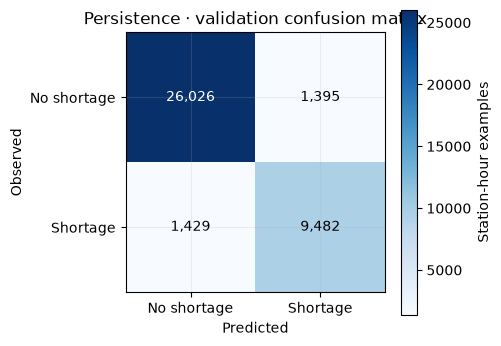

In [9]:
y = val["shortage_in_1h"].astype(int).to_numpy()
pred = (val["current_bikes"].to_numpy() <= 2).astype(int)

tp = int(((pred == 1) & (y == 1)).sum())
fp = int(((pred == 1) & (y == 0)).sum())
fn = int(((pred == 0) & (y == 1)).sum())
tn = int(((pred == 0) & (y == 0)).sum())

def safe_div(a, b):
    return a / b if b else float("nan")

precision = safe_div(tp, tp + fp)
recall = safe_div(tp, tp + fn)
f1 = safe_div(2 * precision * recall, precision + recall)
accuracy = safe_div(tp + tn, len(y))

scores = pd.DataFrame([
    ("Accuracy", accuracy, "All correct predictions / all predictions"),
    ("Precision", precision, "True shortage alerts / all shortage alerts"),
    ("Recall", recall, "Detected shortages / all actual shortages"),
    ("F1", f1, "Harmonic mean of precision and recall"),
], columns=["Metric", "Value", "Meaning"])
display(scores.style.format({"Value": "{:.3f}"}))

cm = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set(xticks=[0, 1], yticks=[0, 1],
       xticklabels=["No shortage", "Shortage"],
       yticklabels=["No shortage", "Shortage"],
       xlabel="Predicted", ylabel="Observed",
       title="Persistence · validation confusion matrix")
for (row, col), n in np.ndenumerate(cm):
    ax.text(col, row, f"{n:,}", ha="center", va="center",
            color="white" if n > cm.max() / 2 else "black")
fig.colorbar(im, ax=ax, label="Station-hour examples")
plt.tight_layout()
plt.show()

### Why persistence can appear exceptionally strong

The hourly state is derived from a **change-event feed**. If no new event is recorded during the hour, the forward-filled state at the target time will equal the state at the issue time (provided both are considered usable). Consequently, persistence will be *correct by construction* on those pairs.

We therefore break down validation accuracy into pairs where a station had a new recorded event **during the forecast hour** and pairs where it did not. This is a **diagnostic of label construction**, not a predictive feature: at forecast time, we cannot know whether an event will arrive in the next hour.

,event_group,n,persistence_accuracy
0,New station event in forecast hour,24112,88.3%
1,No new station event,14220,100.0%


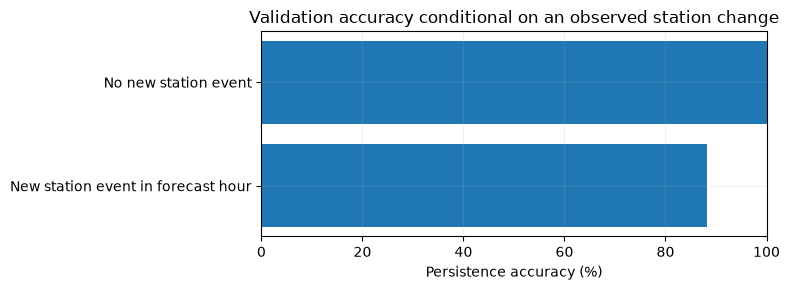

In [10]:
update_breakdown = con.execute("""
    SELECT
        CASE WHEN t.event_time > m.issue_time
             THEN 'New station event in forecast hour'
             ELSE 'No new station event' END AS event_group,
        COUNT(*) AS n,
        AVG(CAST((m.current_bikes <= 2) =
                 (m.shortage_in_1h = 1) AS DOUBLE)) AS persistence_accuracy
    FROM ml m
    JOIN hourly t
      ON m.station_id = t.station_id
     AND m.target_time = t.hour_time
    WHERE m.issue_time > ? AND m.target_time <= ?
    GROUP BY 1
    ORDER BY 1
""", [train_end, val_end]).df()
display(update_breakdown.style.format({"persistence_accuracy": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(update_breakdown.event_group,
        update_breakdown.persistence_accuracy * 100)
ax.set(xlabel="Persistence accuracy (%)", xlim=(0, 100),
       title="Validation accuracy conditional on an observed station change")
plt.tight_layout()
plt.show()

## 6 · Shortage onset: the harder operational question

For a station that already has 0–2 bikes, a one-hour shortage forecast often just says "the current problem will persist." It is more challenging (and sometimes more useful) to predict a **new shortage** among stations that currently have **at least three bikes**.

Two transition rates help us distinguish those scenarios:

- **Onset rate:** fraction of currently non-shortage hours that become shortages next hour.
- **Recovery rate:** fraction of currently shortage hours that return above the threshold next hour.

These rates are properties of the eligible validation pairs, not necessarily of all hours in the city.

In [11]:
currently_ok = val.current_bikes.gt(2)
currently_short = ~currently_ok
onset_count = int(val.loc[currently_ok, "shortage_in_1h"].sum())
recovery_count = int((1 - val.loc[currently_short, "shortage_in_1h"]).sum())
transition_table = pd.DataFrame([
    {"Transition": "New shortage", "Events": onset_count,
     "Eligible starts": int(currently_ok.sum()),
     "Rate": safe_div(onset_count, int(currently_ok.sum()))},
    {"Transition": "Recovery", "Events": recovery_count,
     "Eligible starts": int(currently_short.sum()),
     "Rate": safe_div(recovery_count, int(currently_short.sum()))},
])
display(transition_table.style.format({"Rate": "{:.1%}"}))

,Transition,Events,Eligible starts,Rate
0,New shortage,1429,27455,5.2%
1,Recovery,1395,10877,12.8%


## 7 · Current bike count as an explanatory predictor

Before reaching for a complex algorithm, test what a **simple, domain-informed feature** already tells us. A station with three bikes should generally have a different shortage-onset risk from one with fifteen bikes.

We group the current number of bikes into a few interpretable bins and calculate the historical rate of new shortages. This is an **empirical conditional probability**:

\[
\widehat{P}(\text{new shortage in 1h}\mid\text{current bike group}).
\]

To avoid overfitting to validation, the risk lookup is **estimated using training data only**. Validation data are used solely to check how well those training estimates generalize. The optional +1/+2 smoothing prevents pathological 0%/100% predictions when a group has few observations.

,Train examples,Train onset rate,Estimated risk (+ smoothing),Validation examples,Observed validation rate
bucket,,,,,
3,16098,25.9%,25.9%,2523,29.7%
4,15270,10.5%,10.5%,2279,14.2%
5,14300,4.9%,4.9%,2093,7.1%
6–8,35123,1.8%,1.8%,5340,2.9%
9+,74622,0.3%,0.3%,15220,0.4%


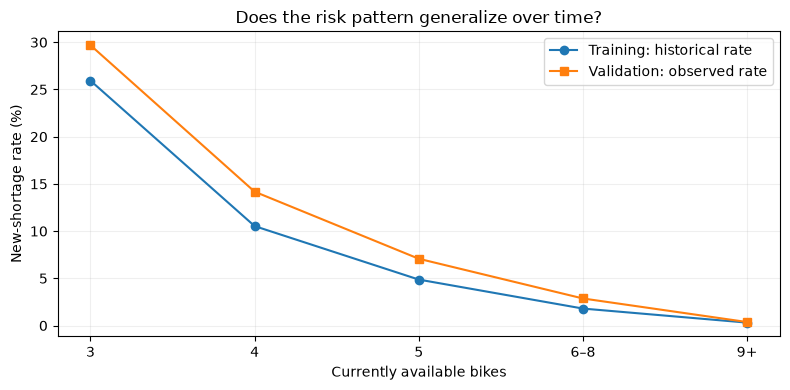

In [12]:
BUCKETS = ["3", "4", "5", "6–8", "9+"]

def add_bucket(data):
    result = data.loc[data.current_bikes > 2].copy()
    result["bucket"] = pd.cut(
        result.current_bikes, bins=[2, 3, 4, 5, 8, float("inf")],
        labels=BUCKETS,
    )
    return result

onset_train = add_bucket(train)
onset_val = add_bucket(val)

tr = (onset_train.groupby("bucket", observed=False)["shortage_in_1h"]
      .agg(n="size", positives="sum").reindex(BUCKETS, fill_value=0))
va = (onset_val.groupby("bucket", observed=False)["shortage_in_1h"]
      .agg(n="size", positives="sum").reindex(BUCKETS, fill_value=0))

train_prior = (onset_train.shortage_in_1h.sum() + 1) / (len(onset_train) + 2)
lookup = ((tr.positives + 1) / (tr.n + 2)).where(tr.n > 0, train_prior)

risk_table = pd.DataFrame({
    "Train examples": tr.n,
    "Train onset rate": tr.positives.div(tr.n.replace(0, np.nan)),
    "Estimated risk (+ smoothing)": lookup,
    "Validation examples": va.n,
    "Observed validation rate": va.positives.div(va.n.replace(0, np.nan)),
})
display(risk_table.style.format({
    "Train onset rate": "{:.1%}",
    "Estimated risk (+ smoothing)": "{:.1%}",
    "Observed validation rate": "{:.1%}",
}, na_rep="—"))

fig, ax = plt.subplots(figsize=(8, 4))
xx = np.arange(len(BUCKETS))
ax.plot(xx, 100 * risk_table["Train onset rate"], marker="o", label="Training: historical rate")
ax.plot(xx, 100 * risk_table["Observed validation rate"], marker="s",
        label="Validation: observed rate")
ax.set(xticks=xx, xticklabels=BUCKETS,
       xlabel="Currently available bikes", ylabel="New-shortage rate (%)",
       title="Does the risk pattern generalize over time?")
ax.legend()
plt.tight_layout()
plt.show()

## 8 · Probabilistic baselines and the Brier score

Our eventual ML model should output a **probability**, not just a yes/no decision. Two simple probabilistic baselines for **onset among currently non-shortage stations** are:

1. **Constant risk:** always predict the overall onset frequency estimated on training data.
2. **Bike-count lookup:** predict the training-set shortage frequency for the corresponding bike-count bin.

The **Brier score** measures the mean squared difference between predicted probability \(p_i\) and binary outcome \(y_i\):

\[
\operatorname{Brier}=\frac{1}{N}\sum_{i=1}^{N}(p_i-y_i)^2.
\]

**Lower is better.** A method that always guesses an unlikely outcome may have high classification accuracy while assigning poor probabilities. The Brier score helps reveal that difference.

,Predictor,Validation Brier score
0,Constant training onset rate,0.04936
1,Training bike-count lookup,0.04203


Relative Brier improvement from bike-count bins: 14.9%


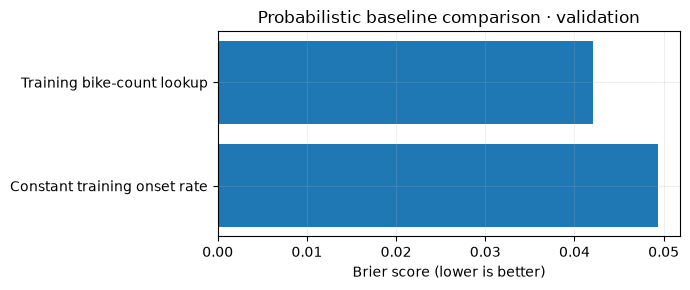

In [13]:
onset_val["pred_constant"] = float(train_prior)
onset_val["pred_bucket"] = onset_val["bucket"].map(lookup.to_dict()).astype(float)

onset_y = onset_val.shortage_in_1h.to_numpy(dtype=float)
p_constant = onset_val.pred_constant.to_numpy(dtype=float)
p_bucket = onset_val.pred_bucket.to_numpy(dtype=float)

brier_constant = float(np.mean((p_constant - onset_y) ** 2))
brier_bucket = float(np.mean((p_bucket - onset_y) ** 2))

brier_table = pd.DataFrame([
    ("Constant training onset rate", brier_constant),
    ("Training bike-count lookup", brier_bucket),
], columns=["Predictor", "Validation Brier score"])
display(brier_table.style.format({"Validation Brier score": "{:.5f}"}))

relative_improvement = safe_div(brier_constant - brier_bucket, brier_constant)
print(f"Relative Brier improvement from bike-count bins: {relative_improvement:.1%}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(brier_table.Predictor, brier_table["Validation Brier score"])
ax.set(xlabel="Brier score (lower is better)",
       title="Probabilistic baseline comparison · validation")
plt.tight_layout()
plt.show()

## 9 · Which information could ML add beyond current availability?

The bike-count baseline is the *starting point*, not the endpoint. More advanced models might learn from **recent changes**, **station identity**, **local hour/day of week**, or interactions among these features.

A useful first diagnostic is to look at the **residual** of the simple probability baseline:

\[
\text{residual}_i = y_i - \hat p_i.
\]

If residuals are systematically positive for a group, actual new shortages occur **more often** than the bike-count baseline expects in that group. Negative means fewer than expected. A systematic pattern *might* indicate that the group contains additional predictive information; it is **not proof** that a particular feature causes shortages or that a more complex model will improve generalization.

Below we look for such patterns by **local hour of day** and **station**. These are diagnostics, not fitted ML feature importances. A meaningful ML improvement must ultimately be demonstrated on chronological validation and a held-out test set.

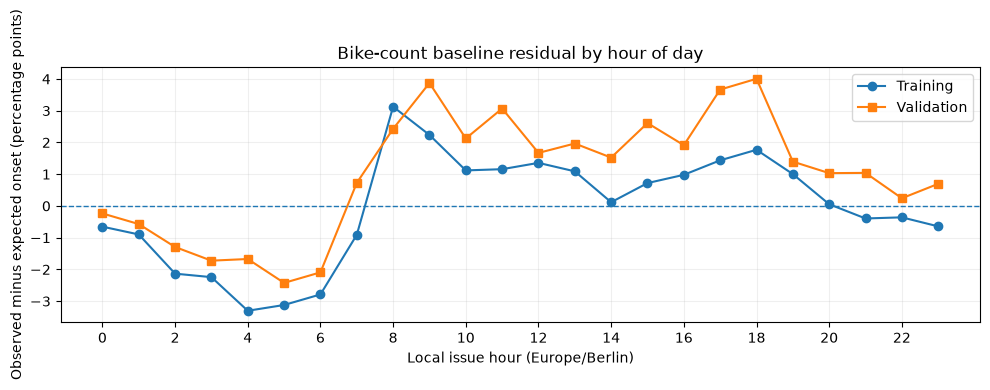

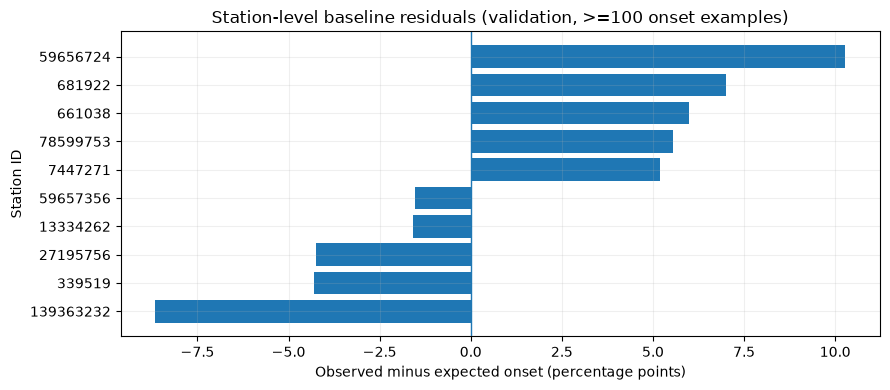

In [14]:
for split in (onset_train, onset_val):
    split["hour_local"] = pd.to_datetime(
        split.issue_time, unit="s", utc=True
    ).dt.tz_convert("Europe/Berlin").dt.hour
    split["pred_bucket"] = split.bucket.map(lookup.to_dict()).astype(float)
    split["residual"] = split.shortage_in_1h - split.pred_bucket

hour_train = onset_train.groupby("hour_local").agg(
    mean_residual=("residual", "mean"), n=("residual", "size")
)
hour_val = onset_val.groupby("hour_local").agg(
    mean_residual=("residual", "mean"), n=("residual", "size")
)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(hour_train.index, 100 * hour_train.mean_residual,
        marker="o", label="Training")
ax.plot(hour_val.index, 100 * hour_val.mean_residual,
        marker="s", label="Validation")
ax.axhline(0, linewidth=1, linestyle="--")
ax.set(xlabel="Local issue hour (Europe/Berlin)",
       ylabel="Observed minus expected onset (percentage points)",
       title="Bike-count baseline residual by hour of day",
       xticks=range(0, 24, 2))
ax.legend()
plt.tight_layout()
plt.show()

# Station patterns: show only stations with enough examples to reduce noise.
station_residual = onset_val.groupby("station_id").agg(
    mean_residual=("residual", "mean"), n=("residual", "size")
)
station_residual = station_residual.loc[station_residual.n >= 100]
if len(station_residual):
    shown = pd.concat([
        station_residual.nsmallest(5, "mean_residual"),
        station_residual.nlargest(5, "mean_residual"),
    ]).drop_duplicates().sort_values("mean_residual")
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(shown.index.astype(str), 100 * shown.mean_residual)
    ax.axvline(0, linewidth=1)
    ax.set(title="Station-level baseline residuals (validation, >=100 onset examples)",
           xlabel="Observed minus expected onset (percentage points)",
           ylabel="Station ID")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough validation onset examples to draw a station residual plot.")

## 10 · What comes next?

Use the notebook as a **methodology report** that can be rerun for any extracted city. Before moving to ML, discuss these questions with your collaborator:

- Does station coverage vary substantially, and what causes low-coverage periods?
- What station- and feed-age thresholds are defensible? Would a stricter threshold change the training sample substantially?
- Is the strong persistence score primarily due to stable states, or is it also strong on hours with genuine station changes?
- How much better is the bike-count probabilistic baseline than an unconditional frequency estimate?
- Do residual patterns by hour or station suggest information that *might* improve predictions beyond bike availability alone?
- How stable are those patterns between training and validation?

**Next ML experiment:** compare a bike-count probability lookup with logistic regression and a tree ensemble using station identity, time-of-day features, **past-only** bike-count lags and changes. Fit transformations exclusively on training data, choose methods using validation, and evaluate the final selected method on the untouched test period.

**Important limitations:** The dataset records station status changes rather than known complete hourly snapshots. Forward-filling, activity-based coverage and maintenance filtering are modelling assumptions. An apparent 100% persistence score on a no-change subset is a property of this reconstructed label definition, not a guarantee of real-world forecasting performance.